# Data Mining Project

#### CLUSTERING: DBSCAN
* Choose the attributes, identify the best parameter configuration (min_pts, eps) and discuss the clusters.

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['grid.color'] = '#444444'   # darker grid
plt.rcParams['grid.linestyle'] = '--'    # tratteggiata fine
plt.rcParams['grid.alpha'] = 0.3         # trasparente, eterea
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Griglia ultra soft per grafici dark
# plt.rcParams['grid.color'] = '#222222'   # ancora più scura e discreta


In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_clustering/DBSCAN/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_clustering/DBSCAN/ already exists.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


In [4]:
#### Scelta delle variabili per il clustering esplorativo
columns_for_clustering = [col for col in df_train.columns if col.endswith("_proc")]

"""
le colonne sono: [
 'startYear_proc',
 'awardWins_proc',
 'numVotes_proc',
 'totalImages_proc',
 'totalVideos_proc',
 'runtimeMinutes_proc',
 'totalCredits_proc',
 'criticReviewsTotal_proc',
 'awardNominationsExcludeWins_proc',
 'numRegions_proc',
 'userReviewsTotal_proc']
"""

X = df_train[columns_for_clustering]

#### DBSCAN search for best min_sample and eps

--- Calculating K-distance for MinPts = 12 ---


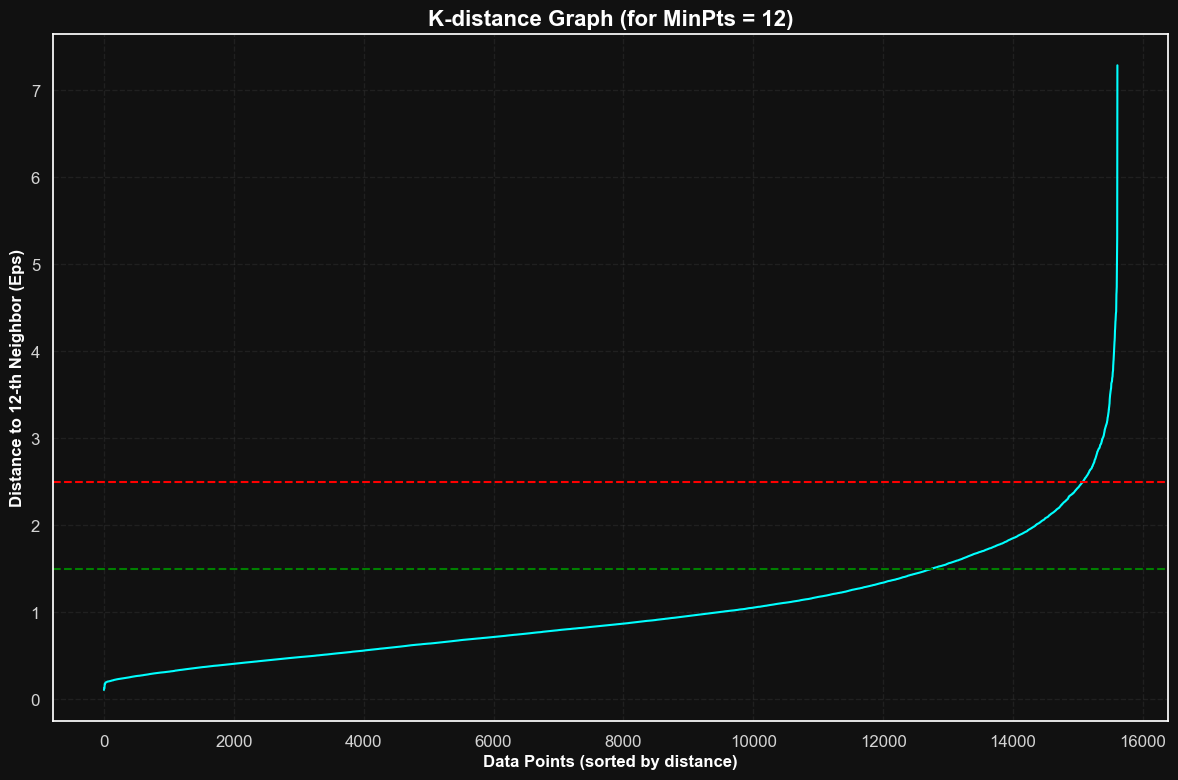


--- Analysis ---
Look for the 'elbow' in the plot above.
This is the point where the curve starts to bend upwards sharply.
The Y-value at this elbow is our optimal choice for Eps.


In [5]:
# A well-known rule is to choose min_sample as min_sample = number_of_columns * 2 or just min_sample >= number_of_columns + 1
min_sample = len(columns_for_clustering) + 1

# --- Finding the optimal Eps value using the K-distance Graph ---
# We have already chosen MinPts based on a standard heuristic.
# Now, we need to find a suitable value for Eps. The best method is to
# plot the distance of each point to its k-th nearest neighbor, where k = MinPts.
# The "elbow" of the resulting curve is our candidate for Eps.
print(f"--- Calculating K-distance for MinPts = {min_sample} ---")

# 1. Use NearestNeighbors to find the distance of each point to its k-th neighbor
# We set n_neighbors to our chosen min_sample value.
neighbors = NearestNeighbors(n_neighbors=min_sample, n_jobs=-1)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

# 2. We are interested in the distance to the k-th neighbor, which is the last column
# of the 'distances' array. We sort these distances in ascending order.
k_distances = np.sort(distances[:, -1])

# 3. Plot the K-distance graph
plt.figure(figsize=(12, 8))
plt.plot(k_distances, color='cyan')
plt.title(f'K-distance Graph (for MinPts = {min_sample})', fontsize=16, weight='bold')
plt.xlabel('Data Points (sorted by distance)', fontsize=12, weight='bold')
plt.ylabel(f'Distance to {min_sample}-th Neighbor (Eps)', fontsize=12, weight='bold')
plt.axhline(y=1.5, color='green', linestyle='--')
plt.axhline(y=2.5, color='red', linestyle='--')
plt.grid(True)
plt.tight_layout()
plt.savefig(f'{plots_dir}dbscan_k_distance_graph.png', dpi=300)
plt.show()

print("\n--- Analysis ---")
print("Look for the 'elbow' in the plot above.")
print("This is the point where the curve starts to bend upwards sharply.")
print("The Y-value at this elbow is our optimal choice for Eps.")


#### DBSCAN using eps = 1.5 and min_sample = 12

--- Running DBSCAN with Eps=1.5 and MinPts=12 ---
This may take a moment...
--- DBSCAN Clustering Complete ---

Estimated number of clusters: 3
Estimated number of noise points: 1884 (12.07%)

--- Analyzing Full Cluster and Noise Distribution ---

Counts for each label (including -1 for Noise):
dbscan
-1     1884
 0    12369
 1      767
 2      589
Name: count, dtype: int64

Percentage for each label:
dbscan
-1    12.07 %
 0    79.24 %
 1     4.91 %
 2     3.77 %
Name: proportion, dtype: object


/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_89395/2053892389.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=full_distribution_counts.index, y=full_distribution_counts.values, palette='flare')


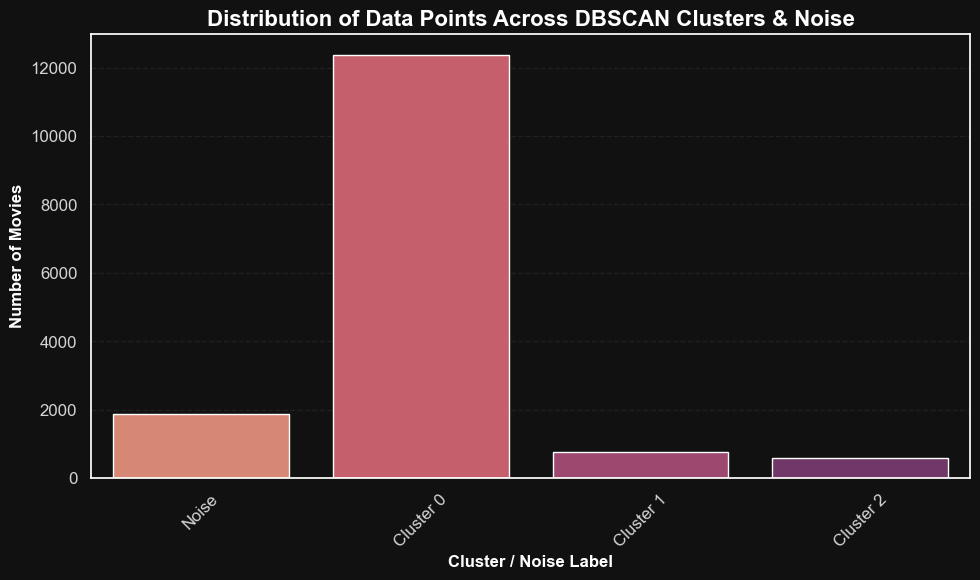

--- Generating 2D Visualization for DBSCAN Results ---


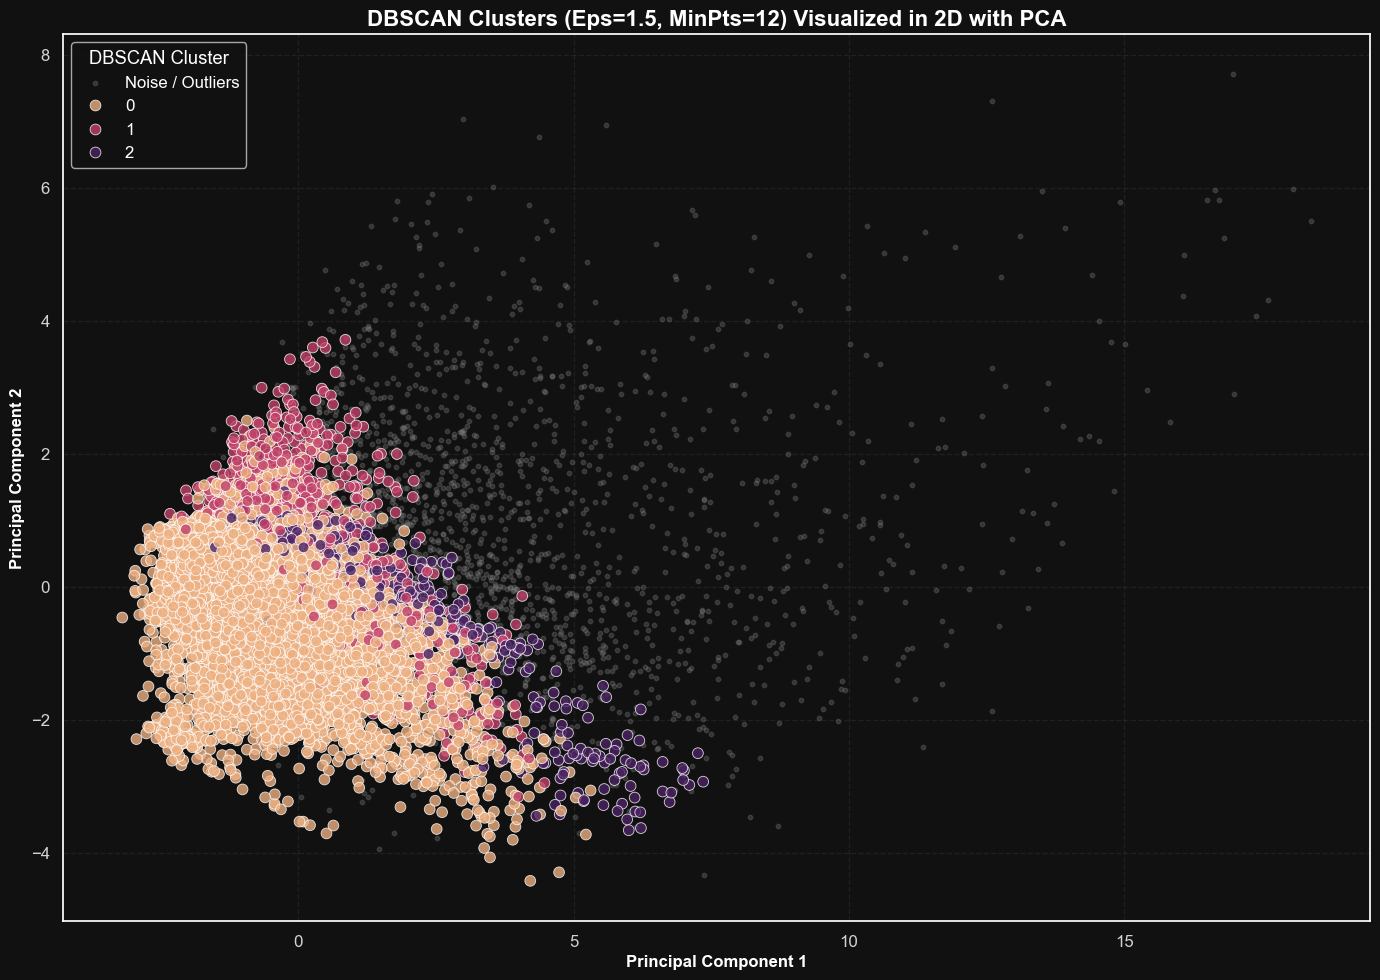

In [7]:
# --- Performing DBSCAN Clustering with Optimal Parameters ---
# Based on our analysis, we have selected our two critical parameters.

# Our chosen parameters
MIN_PTS = 12
EPS = 1.5 # This value is an example based on a possible elbow point

print(f"--- Running DBSCAN with Eps={EPS} and MinPts={MIN_PTS} ---")
print("This may take a moment...")

# 1. Instantiate and run the DBSCAN model
dbscan = DBSCAN(eps=EPS, min_samples=MIN_PTS, n_jobs=-1)
cluster_labels = dbscan.fit_predict(X)

# 2. Add the cluster labels to our dataframe with the specific name 'dbscan'
# The label -1 is reserved by DBSCAN for noise points (outliers).
df_train['dbscan'] = cluster_labels

print("--- DBSCAN Clustering Complete ---")

# 3. Analyze the results
# We count the number of points in each cluster and the number of noise points.
n_clusters_ = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise_ = list(cluster_labels).count(-1)

print(f"\nEstimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_} ({n_noise_/len(df_train)*100:.2f}%)")


# --- 4. Analyze and Visualize Cluster Distribution (New Addition) ---
# It is crucial to understand the size of each discovered cluster and the noise.

print("\n--- Analyzing Full Cluster and Noise Distribution ---")

# Calculate counts and percentages for each cluster label (including noise label -1)
full_distribution_counts = df_train['dbscan'].value_counts().sort_index()
full_distribution_perc = df_train['dbscan'].value_counts(normalize=True).sort_index() * 100

print("\nCounts for each label (including -1 for Noise):")
print(full_distribution_counts)
print("\nPercentage for each label:")
print(full_distribution_perc.round(2).astype(str) + ' %')

# --- Plotting the Distribution ---
plt.figure(figsize=(10, 6))
sns.barplot(x=full_distribution_counts.index, y=full_distribution_counts.values, palette='flare')
plt.title('Distribution of Data Points Across DBSCAN Clusters & Noise', fontsize=16, weight='bold')
plt.xlabel('Cluster / Noise Label', fontsize=12, weight='bold')
plt.ylabel('Number of Movies', fontsize=12, weight='bold')

# Create custom labels for the x-axis
xtick_labels = [f'Cluster {i}' if i != -1 else 'Noise' for i in full_distribution_counts.index]
plt.xticks(ticks=range(len(full_distribution_counts)), labels=xtick_labels, rotation=45)

plt.tight_layout()
plt.savefig(f'{plots_dir}dbscan_cluster_distribution.png', dpi=300)
plt.show()


# --- Visualizing DBSCAN Clusters using PCA ---
# We will use PCA again to project our 11-dimensional data into a 2D space.
# This visualization is particularly insightful for DBSCAN as it allows us to see
# not only the shape and location of the found clusters but also the distribution
# of the points classified as noise.

print("--- Generating 2D Visualization for DBSCAN Results ---")

# 1. Reduce dimensionality to 2 components using the same PCA logic
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X)

# 2. Create a DataFrame for plotting, using our specific 'dbscan' column
df_pca_2d = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
df_pca_2d['dbscan_cluster'] = df_train['dbscan'] # Using the correct column name

# 3. Separate the noise points from the clustered points for distinct plotting
noise_points = df_pca_2d[df_pca_2d['dbscan_cluster'] == -1]
clustered_points = df_pca_2d[df_pca_2d['dbscan_cluster'] != -1]

# --- Plotting the 2D Clusters and Noise ---
plt.figure(figsize=(14, 10))

# First, plot the noise points in a subtle color (e.g., gray)
plt.scatter(noise_points['PC1'], noise_points['PC2'],
            color='gray', s=10, alpha=0.3, label='Noise / Outliers')

# Then, plot the actual clusters on top
sns.scatterplot(data=clustered_points, x='PC1', y='PC2', hue='dbscan_cluster',
                palette='flare', s=60, alpha=0.8)

plt.title(f'DBSCAN Clusters (Eps={EPS}, MinPts={MIN_PTS}) Visualized in 2D with PCA', fontsize=16, weight='bold')
plt.xlabel('Principal Component 1', fontsize=12, weight='bold')
plt.ylabel('Principal Component 2', fontsize=12, weight='bold')
plt.legend(title='DBSCAN Cluster')
plt.grid(True)
plt.tight_layout()
plt.savefig(f'{plots_dir}dbscan_2d_pca_visualization.png', dpi=300)
plt.show()

In [8]:
# --- Self-Contained Cross-Algorithm Analysis ---
#
# Since the 'kmeans' labels from the previous notebook are not available,
# this cell will first re-generate them and then perform the cross-analysis
# to test our hypothesis.

print("--- Phase 1: Re-generating K-Means labels (k=7) ---")

# 1. Define the parameters for our winning K-Means model
OPTIMAL_K = 7
kmeans_model = KMeans(n_clusters=OPTIMAL_K, random_state=42, init="k-means++", n_init='auto', max_iter=300, verbose=0)
print('K-Means model parameters:')

# 2. Fit K-Means and generate the labels
kmeans_labels = kmeans_model.fit_predict(X)

# 3. Add the 'kmeans' column to our current dataframe for the analysis
df_train['kmeans'] = kmeans_labels

print("K-Means labels successfully generated and added to the dataframe.")


# --- Phase 2: Investigating the Fate of K-Means Elite Clusters in DBSCAN ---
print("\n--- Phase 2: Cross-Analysis with DBSCAN results ---")

# 1. Identify our two "elite" clusters from the K-Means analysis
# Cluster 1: The Hollywood Elite
# Cluster 3: The Festival Darlings
# Note: Cluster IDs might change on re-run, but they are identifiable by their small size.
# We will identify them dynamically.
kmeans_counts = df_train['kmeans'].value_counts()
# The elite clusters are the two smallest ones.
kmeans_elite_clusters_ids = kmeans_counts.nsmallest(2).index.tolist()
print(f"Dynamically identified K-Means elite clusters as: {kmeans_elite_clusters_ids}")


# 2. Create a dataframe containing ONLY the movies from these elite clusters
df_elite = df_train[df_train['kmeans'].isin(kmeans_elite_clusters_ids)].copy()

# 3. Now, let's look at the 'dbscan' labels assigned to THIS specific group of movies
# We assume the 'dbscan' column already exists from the previous steps.
dbscan_verdict_on_elites = df_elite['dbscan'].value_counts()
dbscan_verdict_on_elites_perc = df_elite['dbscan'].value_counts(normalize=True) * 100

print(f"\nAnalysis of the {len(df_elite)} movies from K-Means elite clusters:")
print("\nHow DBSCAN classified them:")
print(dbscan_verdict_on_elites)
print("\nIn percentage terms:")
print(dbscan_verdict_on_elites_perc.round(2).astype(str) + ' %')

# --- Conclusion ---
# Check the percentage of points labeled as -1 (Noise)
if -1 in dbscan_verdict_on_elites_perc.index:
    noise_perc = dbscan_verdict_on_elites_perc.loc[-1]
    if noise_perc > 50:
        print(f"\nHYPOTHESIS CONFIRMED: A staggering {noise_perc:.2f}% of the K-Means elite movies were classified as NOISE by DBSCAN.")
    else:
        print(f"\nHYPOTHESIS PARTIALLY CONFIRMED: A significant {noise_perc:.2f}% of the K-Means elite movies were classified as NOISE by DBSCAN.")
else:
    print("\nHYPOTHESIS DISPROVEN: The K-Means elite movies were successfully grouped into clusters by DBSCAN.")

--- Phase 1: Re-generating K-Means labels (k=7) ---
K-Means model parameters:
K-Means labels successfully generated and added to the dataframe.

--- Phase 2: Cross-Analysis with DBSCAN results ---
Dynamically identified K-Means elite clusters as: [1, 3]

Analysis of the 988 movies from K-Means elite clusters:

How DBSCAN classified them:
dbscan
-1    887
 1     98
 0      3
Name: count, dtype: int64

In percentage terms:
dbscan
-1    89.78 %
 1     9.92 %
 0      0.3 %
Name: proportion, dtype: object

HYPOTHESIS CONFIRMED: A staggering 89.78% of the K-Means elite movies were classified as NOISE by DBSCAN.


#### Deep Cluster Analysis

In [11]:
from scipy.spatial import distance

# --- Deep Cluster Analysis for DBSCAN ---
# This cell performs a comprehensive analysis of the clusters and noise identified
# by our final DBSCAN configuration. We will treat the noise points (label -1)
# as a distinct group to understand what kind of movies are being excluded
# from the dense regions.

print("="*80)
print(" " * 22 + "DEEP CLUSTER ANALYSIS (DBSCAN)")
print("="*80)

# --- SETUP FOR ANALYSIS ---

# List of the original numerical columns we want to analyze.
original_numerical_cols = [
 'startYear', 'runtimeMinutes', 'numVotes', 'awardWins',
 'awardNominationsExcludeWins', 'userReviewsTotal', 'criticReviewsTotal',
 'totalImages', 'totalCredits', 'numRegions'
]

# Define the categorical feature groups we want to analyze
titletype_cols = [col for col in df_train.columns if 'titleType_' in col]
genre_cols = [col for col in df_train.columns if 'genres_' in col]
country_cols = [col for col in df_train.columns if 'countryOfOrigin_' in col]

# Get the unique labels found by DBSCAN, including noise, and sort them
unique_labels = sorted(df_train['dbscan'].unique())


# --- ANALYSIS LOOP FOR EACH CLUSTER AND NOISE ---

for i in unique_labels:
    # Isolate the data for the current label
    cluster_df = df_train[df_train['dbscan'] == i]

    # Customize the title based on whether it's a cluster or noise
    if i == -1:
        print(f"\n\n--- NOISE GROUP (-1) ANALYSIS ---")
    else:
        print(f"\n\n--- CLUSTER {i} ANALYSIS ---")

    print(f"Number of movies in this group: {len(cluster_df)} ({len(cluster_df)/len(df_train)*100:.2f}%)")
    print("-" * 50)

    # --- 1. Quantitative Profile (The "What") ---
    print("\n[+] Quantitative Profile (Average values on original scale):")
    profile = cluster_df[original_numerical_cols].mean()
    print(profile.round(1))

    # --- 2. Categorical Profile (The "Who") ---
    print("\n[+] Categorical Profile (Top 3 categories in each group):")

    # TitleType Analysis
    titletype_dist = cluster_df[titletype_cols].sum().sort_values(ascending=False)
    print("\n  - Top Title Types:")
    for idx, val in titletype_dist.head(3).items():
        print(f"    - {idx.replace('titleType_', '')}: {val/len(cluster_df)*100:.1f}%")

    # Genre Analysis
    genre_dist = cluster_df[genre_cols].sum().sort_values(ascending=False)
    print("\n  - Top Genres:")
    for idx, val in genre_dist.head(3).items():
        print(f"    - {idx.replace('genres_', '')}: {val/len(cluster_df)*100:.1f}%")

    # --- 3. Exemplars (The "Face") ---
    if i == -1:
        # For noise, show random samples as there is no "center"
        print("\n[+] Exemplars (Random samples from the Noise group):")
        exemplars = cluster_df.sample(min(5, len(cluster_df)), random_state=42)[['originalTitle', 'startYear', 'numVotes', 'rating_encoded']]
    else:
        # For actual clusters, find the "medoid" - the most central point.
        print("\n[+] Exemplars (Most representative movies - near medoid):")

        # Get the processed data points for the current cluster
        cluster_points_proc = X[df_train['dbscan'] == i]

        # Calculate the mean of the cluster points to find a "pseudo-centroid"
        pseudo_centroid = cluster_points_proc.mean().values.reshape(1, -1)

        # Calculate the distance of each point in the cluster to this pseudo-centroid
        distances = distance.cdist(cluster_points_proc, pseudo_centroid)

        # Get the indices of the 3 closest points
        closest_indices_in_cluster = np.argsort(distances, axis=0)[:3].flatten()

        # Get the original indices from the main dataframe
        original_indices = cluster_df.iloc[closest_indices_in_cluster].index

        # Print the top 3 exemplars
        exemplars = df_train.loc[original_indices][['originalTitle', 'startYear', 'numVotes', 'rating_encoded']]

    for index, row in exemplars.iterrows():
        print(f"    - {row['originalTitle']} ({int(row['startYear'])}) - Votes: {int(row['numVotes'])}, Rating Encoded: {row['rating_encoded']}")

print("\n" + "="*80)
print(" " * 30 + "ANALYSIS COMPLETE")
print("="*80)

                      DEEP CLUSTER ANALYSIS (DBSCAN)


--- NOISE GROUP (-1) ANALYSIS ---
Number of movies in this group: 1884 (12.07%)
--------------------------------------------------

[+] Quantitative Profile (Average values on original scale):
startYear                       2000.1
runtimeMinutes                    78.2
numVotes                       11421.4
awardWins                          3.0
awardNominationsExcludeWins        4.2
userReviewsTotal                  47.5
criticReviewsTotal                17.4
totalImages                       44.3
totalCredits                     147.1
numRegions                        11.5
dtype: float64

[+] Categorical Profile (Top 3 categories in each group):

  - Top Title Types:
    - movie: 64.2%
    - tvSeries: 12.7%
    - short: 10.9%

  - Top Genres:
    - Drama: 54.4%
    - Comedy: 26.2%
    - Romance: 13.1%

[+] Exemplars (Random samples from the Noise group):
    - There Is No Friend's House (2023) - Votes: 10, Rating Encoded: 6
    